# 高周波における受動部品の周波数特性

インダクタ、キャパシタ、レジスタは、高周波では寄生成分のため理想素子と異なる振る舞いを示します。このノートでは、等価回路から複素インピーダンスを計算し、数値例をグラフ化します。

**到達目標**

- 各部品の高周波等価回路を説明できる。
- $Z(\omega)$ の大きさと位相を計算できる。
- 自己共振周波数の前後で支配的な成分が変わることをグラフから読み取れる。

> 以下の数値は傾向を観察するための例です。実設計では、使用する部品のデータシートやSパラメータを確認してください。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle

plt.rcParams.update({
    'figure.figsize': (10, 6),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 12,
})

f = np.logspace(6, 11, 2500)  # 1 MHz ～ 100 GHz
omega = 2 * np.pi * f

def plot_impedance(f, z_ideal, z_real, title, marker_frequency=None, marker_label='SRF'):
    fig, (ax_mag, ax_phase) = plt.subplots(2, 1, sharex=True, figsize=(10, 7))
    ax_mag.loglog(f, np.abs(z_ideal), '--', label='ideal model')
    ax_mag.loglog(f, np.abs(z_real), linewidth=2, label='realistic model')
    ax_mag.set_ylabel(r'$|Z|\;[\Omega]$')
    ax_mag.legend()
    ax_mag.set_title(title)
    ax_phase.semilogx(f, np.angle(z_ideal, deg=True), '--', label='ideal model')
    ax_phase.semilogx(f, np.angle(z_real, deg=True), linewidth=2, label='realistic model')
    ax_phase.set_xlabel('frequency [Hz]')
    ax_phase.set_ylabel('phase [deg]')
    ax_phase.set_ylim(-100, 100)
    if marker_frequency is not None:
        for ax in (ax_mag, ax_phase):
            ax.axvline(marker_frequency, color='tab:red', linestyle=':',
                       label=f'{marker_label} = {marker_frequency/1e6:.1f} MHz')
        ax_mag.legend()
    plt.tight_layout()
    plt.show()

def wire(ax, x1, y1, x2, y2):
    ax.plot([x1, x2], [y1, y2], color='black', linewidth=2)

def node(ax, x, y, radius=0.065):
    ax.add_patch(Circle((x, y), radius, facecolor='black', edgecolor='black', zorder=5))

def resistor(ax, x, y, width=1.2, height=0.55, label='R'):
    ax.add_patch(Rectangle((x, y-height/2), width, height, fill=False, linewidth=2))
    ax.text(x+width/2, y+0.55, label, ha='center', va='bottom', fontsize=15)

def capacitor(ax, x, y, width=1.2, label='C'):
    wire(ax, x, y, x+0.48*width, y)
    wire(ax, x+0.48*width, y-0.45, x+0.48*width, y+0.45)
    wire(ax, x+0.58*width, y-0.45, x+0.58*width, y+0.45)
    wire(ax, x+0.58*width, y, x+width, y)
    ax.text(x+width/2, y+0.65, label, ha='center', va='bottom', fontsize=15)

def inductor(ax, x, y, width=1.5, label='L'):
    lead = 0.15 * width
    wire(ax, x, y, x+lead, y)
    t = np.linspace(0, 4*np.pi, 240)
    xx = x + lead + (width-2*lead) * t/(4*np.pi)
    yy = y + 0.32 * np.sin(t)
    ax.plot(xx, yy, color='black', linewidth=2)
    wire(ax, x+width-lead, y, x+width, y)
    ax.text(x+width/2, y+0.65, label, ha='center', va='bottom', fontsize=15)

def finish_circuit(ax, title, nodes=((0.5, 2), (9.5, 2))):
    for x, y in nodes:
        node(ax, x, y)
    ax.set_xlim(0, 10)
    ax.set_ylim(-0.35, 3.65)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(title, fontsize=17, weight='bold')

## 1. 実在インダクタ

巻線抵抗 $R_s$ とインダクタンス $L$ の直列枝に、巻線間容量 $C_p$ と損失を表す $R_p$ が並列に接続されるモデルです。

$$
Z_L(\omega)=\left[\frac{1}{R_s+j\omega L}+\frac{1}{R_p}+j\omega C_p\right]^{-1}
$$

損失を無視した自己共振周波数の近似は $f_{\mathrm{SRF}}\simeq 1/(2\pi\sqrt{LC_p})$ です。

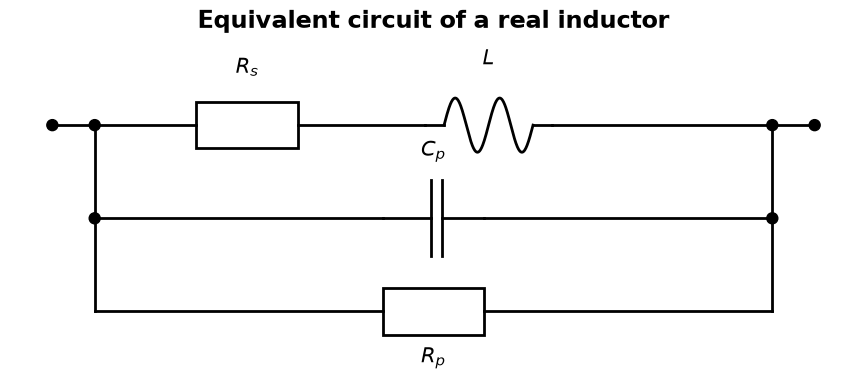

In [2]:
fig, ax = plt.subplots(figsize=(11, 4.4))
x_left, x_right = 1.0, 9.0
y_top, y_middle, y_bottom = 2.6, 1.5, 0.4
# 左右の母線と外部端子
wire(ax, 0.5, y_top, x_left, y_top); wire(ax, x_left, y_bottom, x_left, y_top)
wire(ax, x_right, y_bottom, x_right, y_top); wire(ax, x_right, y_top, 9.5, y_top)
# 上段: Rs と L の直列枝
wire(ax, x_left, y_top, 2.2, y_top); resistor(ax, 2.2, y_top, label=r'$R_s$')
wire(ax, 3.4, y_top, 4.9, y_top); inductor(ax, 4.9, y_top, label=r'$L$')
wire(ax, 6.4, y_top, x_right, y_top)
# 中段: 巻線間容量 Cp
wire(ax, x_left, y_middle, 4.4, y_middle)
capacitor(ax, 4.4, y_middle, label=r'$C_p$')
wire(ax, 5.6, y_middle, x_right, y_middle)
# 下段: 損失抵抗 Rp（ラベルは配線から離して下側へ）
wire(ax, x_left, y_bottom, 4.4, y_bottom)
resistor(ax, 4.4, y_bottom, label='')
ax.text(5.0, -0.02, r'$R_p$', ha='center', va='top', fontsize=15)
wire(ax, 5.6, y_bottom, x_right, y_bottom)
junctions = [(0.5, y_top), (9.5, y_top)]
junctions += [(x_left, y) for y in (y_top, y_middle)]
junctions += [(x_right, y) for y in (y_top, y_middle)]
finish_circuit(ax, 'Equivalent circuit of a real inductor', nodes=junctions)
plt.show()

Inductor approximate SRF: 711.8 MHz


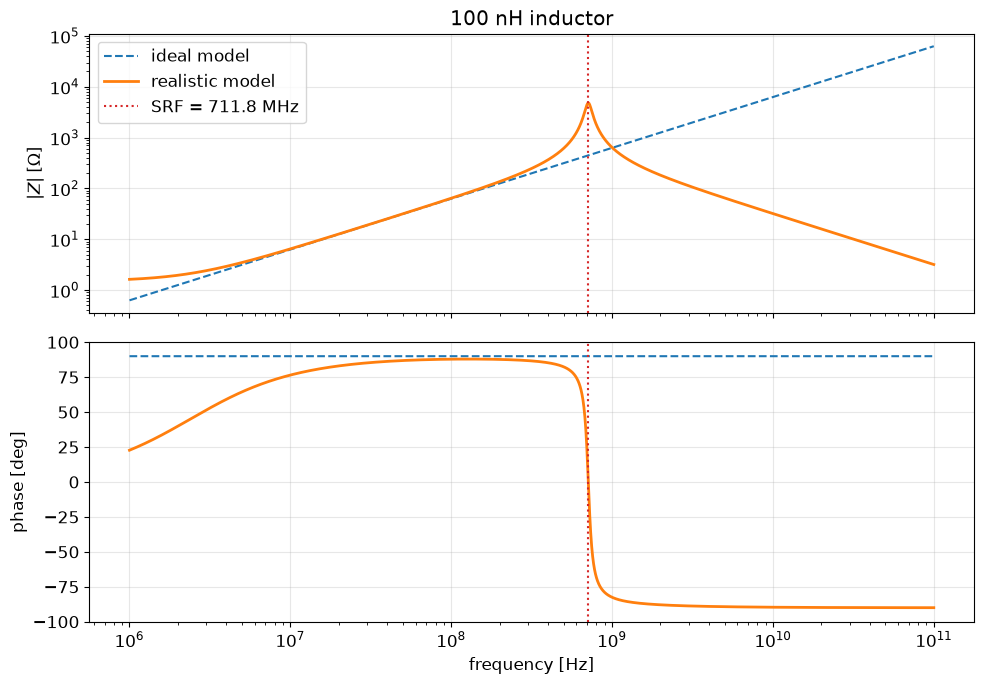

In [3]:
# 数値例: 100 nH のインダクタ
L = 100e-9       # H
Rs = 1.5         # ohm
Cp_L = 0.5e-12   # F
Rp = 5e3         # ohm

ZL_ideal = 1j * omega * L
ZL_real = 1 / (1/(Rs + 1j*omega*L) + 1/Rp + 1j*omega*Cp_L)
f_srf_L = 1 / (2*np.pi*np.sqrt(L*Cp_L))
print(f'Inductor approximate SRF: {f_srf_L/1e6:.1f} MHz')
plot_impedance(f, ZL_ideal, ZL_real, '100 nH inductor', f_srf_L)

**読み取り**：低周波側では $|Z|\approx\omega L$ ですが、自己共振付近でインピーダンスが最大になり、それより高い周波数では $C_p$ が支配的になって容量性へ反転します。

## 2. 実在キャパシタ

誘電体や電極の損失を表す等価直列抵抗 $R_{\mathrm{ESR}}$、端子や電極の寄生インダクタンス $L_{\mathrm{ESL}}$、理想容量 $C$ の直列モデルです。

$$
Z_C(\omega)=R_{\mathrm{ESR}}+j\omega L_{\mathrm{ESL}}+\frac{1}{j\omega C}
$$

自己共振周波数は $f_{\mathrm{SRF}}=1/(2\pi\sqrt{L_{\mathrm{ESL}}C})$ です。

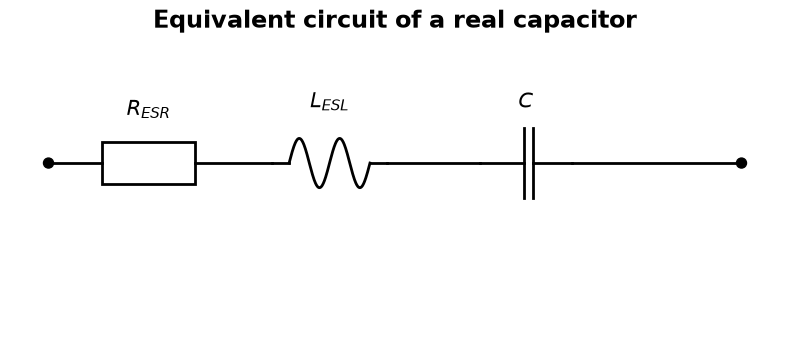

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
wire(ax, 0.5, 2, 1.2, 2); resistor(ax, 1.2, 2, label=r'$R_{ESR}$')
wire(ax, 2.4, 2, 3.4, 2); inductor(ax, 3.4, 2, label=r'$L_{ESL}$')
wire(ax, 4.9, 2, 6.1, 2); capacitor(ax, 6.1, 2, label=r'$C$'); wire(ax, 7.3, 2, 9.5, 2)
finish_circuit(ax, 'Equivalent circuit of a real capacitor')
plt.show()

Capacitor SRF: 562.7 MHz


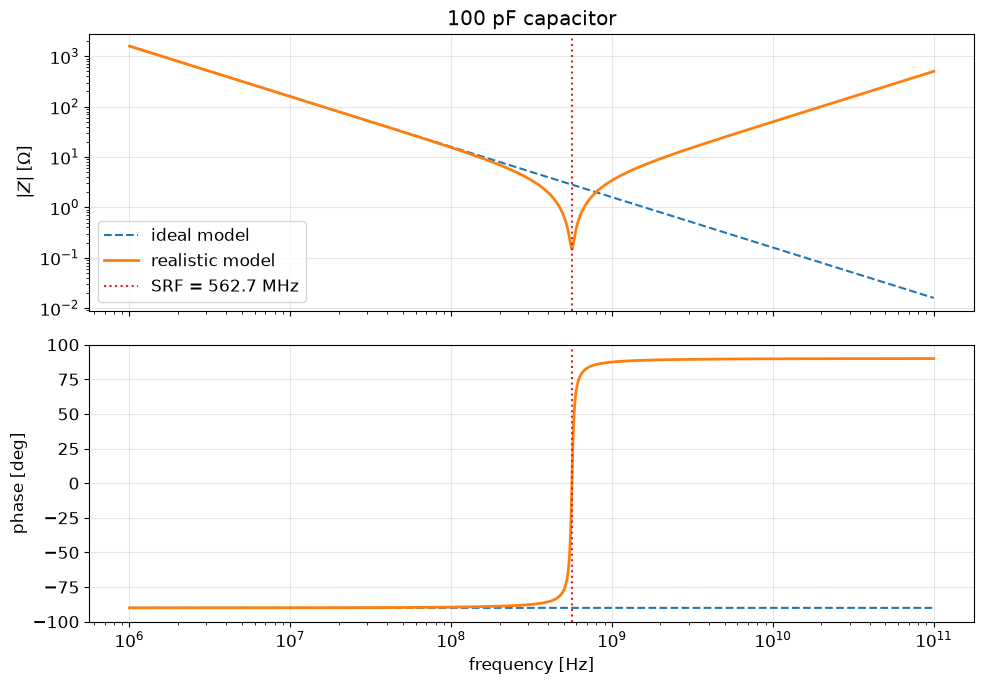

In [5]:
# 数値例: 100 pF のキャパシタ
C = 100e-12      # F
ESR = 0.15       # ohm
ESL = 0.8e-9     # H

ZC_ideal = 1 / (1j * omega * C)
ZC_real = ESR + 1j*omega*ESL + 1/(1j*omega*C)
f_srf_C = 1 / (2*np.pi*np.sqrt(ESL*C))
print(f'Capacitor SRF: {f_srf_C/1e6:.1f} MHz')
plot_impedance(f, ZC_ideal, ZC_real, '100 pF capacitor', f_srf_C)

**読み取り**：自己共振より低い周波数では容量性、共振点では $|Z|$ がほぼESRまで低下し、より高い周波数ではESLが支配的になって誘導性へ反転します。

## 3. 実在レジスタ

リードや電極の寄生インダクタンス $L_s$ と、抵抗体をまたぐ寄生容量 $C_p$ を含むモデルです。ここでは $L_s$ と、$R$ と $C_p$ の並列回路が直列に接続されるとします。

$$
Z_R(\omega)=j\omega L_s+\left(\frac{1}{R}+j\omega C_p\right)^{-1}
$$

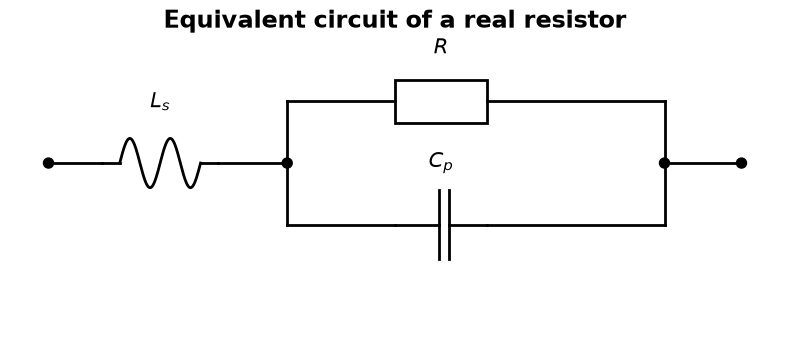

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
wire(ax, 0.5, 2, 1.2, 2); inductor(ax, 1.2, 2, label=r'$L_s$'); wire(ax, 2.7, 2, 3.6, 2)
# R と Cp の並列部分
wire(ax, 3.6, 2, 3.6, 2.8); wire(ax, 3.6, 2.8, 5.0, 2.8)
resistor(ax, 5.0, 2.8, label=r'$R$'); wire(ax, 6.2, 2.8, 8.5, 2.8); wire(ax, 8.5, 2.8, 8.5, 2)
wire(ax, 3.6, 2, 3.6, 1.2); wire(ax, 3.6, 1.2, 5.0, 1.2)
capacitor(ax, 5.0, 1.2, label=r'$C_p$'); wire(ax, 6.2, 1.2, 8.5, 1.2); wire(ax, 8.5, 1.2, 8.5, 2)
wire(ax, 8.5, 2, 9.5, 2)
finish_circuit(ax, 'Equivalent circuit of a real resistor',
               nodes=[(0.5, 2), (3.6, 2), (8.5, 2), (9.5, 2)])
plt.show()

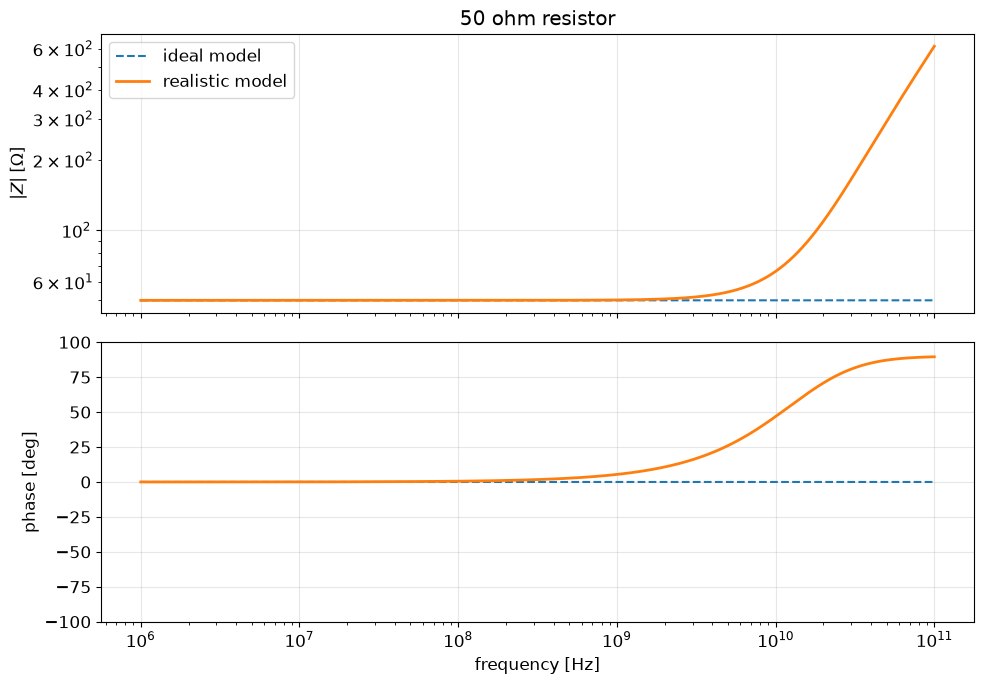

In [7]:
# 数値例: 50 ohm のレジスタ
R = 50.0        # ohm
Cp_R = 0.1e-12  # F
Ls = 1.0e-9     # H

ZR_ideal = np.full_like(omega, R, dtype=complex)
ZR_real = 1j*omega*Ls + 1/(1/R + 1j*omega*Cp_R)
plot_impedance(f, ZR_ideal, ZR_real, '50 ohm resistor')

**読み取り**：低周波側では $Z\approx R$ ですが、高周波では $C_p$ による電流の迂回と $L_s$ によるリアクタンスが無視できません。この数値例では、数GHzを超えると大きさと位相が理想抵抗から明確にずれます。

## 確認課題

1. インダクタの $C_p$ を2倍にすると、自己共振周波数は何倍になるか予想し、コードで確認してください。
2. キャパシタの $L_{\mathrm{ESL}}$ を半分にすると、使用可能な周波数範囲はどう変わるか確認してください。
3. レジスタについて、$L_s=0$ とした場合と $C_p=0$ とした場合を別々に描き、どちらの寄生成分が各周波数帯で支配的か説明してください。